# Лабораторная работа № 3. Объединение и группировка данных. Объединение нескольких dataframe

In [3]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (10, 5)

<Axes: xlabel='Date'>

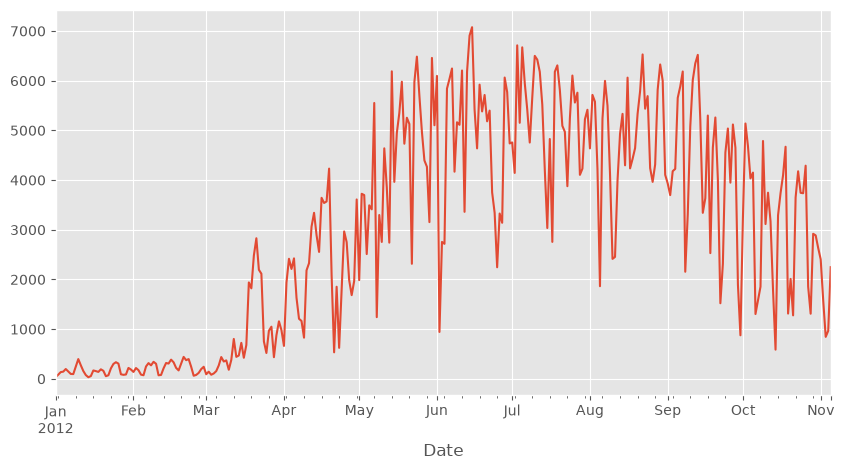

In [4]:
bikes = pd.read_csv('data/bikes.csv', sep=';', encoding='latin1', parse_dates=['Date'],
                    dayfirst=True, index_col='Date')
bikes['Berri 1'].plot()

In [86]:
bikes.loc["2012-01-02"]

Berri 1                                 83.0
Brébeuf (données non disponibles)        NaN
Côte-Sainte-Catherine                    1.0
Maisonneuve 1                           68.0
Maisonneuve 2                          153.0
du Parc                                 53.0
Pierre-Dupuy                             6.0
Rachel1                                 43.0
St-Urbain (données non disponibles)      NaN
Name: 2012-01-02 00:00:00, dtype: float64

In [ ]:
berri_bikes = bikes[['Berri 1']].copy()

In [7]:
berri_bikes.index

DatetimeIndex(['2012-01-01', '2012-01-02', '2012-01-03', '2012-01-04',
               '2012-01-05', '2012-01-06', '2012-01-07', '2012-01-08',
               '2012-01-09', '2012-01-10',
               ...
               '2012-10-27', '2012-10-28', '2012-10-29', '2012-10-30',
               '2012-10-31', '2012-11-01', '2012-11-02', '2012-11-03',
               '2012-11-04', '2012-11-05'],
              dtype='datetime64[us]', name='Date', length=310, freq=None)

In [8]:
berri_bikes.index.day

Index([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10,
       ...
       27, 28, 29, 30, 31,  1,  2,  3,  4,  5],
      dtype='int32', name='Date', length=310)

In [9]:
berri_bikes.index.weekday

Index([6, 0, 1, 2, 3, 4, 5, 6, 0, 1,
       ...
       5, 6, 0, 1, 2, 3, 4, 5, 6, 0],
      dtype='int32', name='Date', length=310)

In [10]:
berri_bikes.loc[:, 'weekday'] = berri_bikes.index.weekday
berri_bikes[:5]

,Berri 1,weekday
Date,,
2012-01-01,35,6
2012-01-02,83,0
2012-01-03,135,1
2012-01-04,144,2
2012-01-05,197,3


In [11]:
weekday_counts = berri_bikes.groupby('weekday').aggregate(sum)

weekday_counts

,Berri 1
weekday,
0,134298
1,135305
2,152972
3,160131
4,141771
5,101578
6,99310


In [12]:
weekday_counts.index = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday',
                        'Sunday']
weekday_counts

,Berri 1
Monday,134298
Tuesday,135305
Wednesday,152972
Thursday,160131
Friday,141771
Saturday,101578
Sunday,99310


<Axes: >

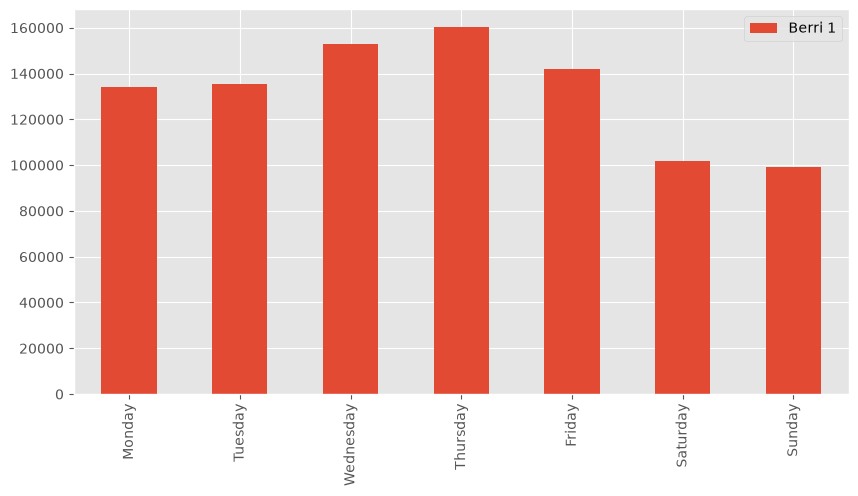

In [13]:
weekday_counts.plot(kind='bar')

<Axes: >

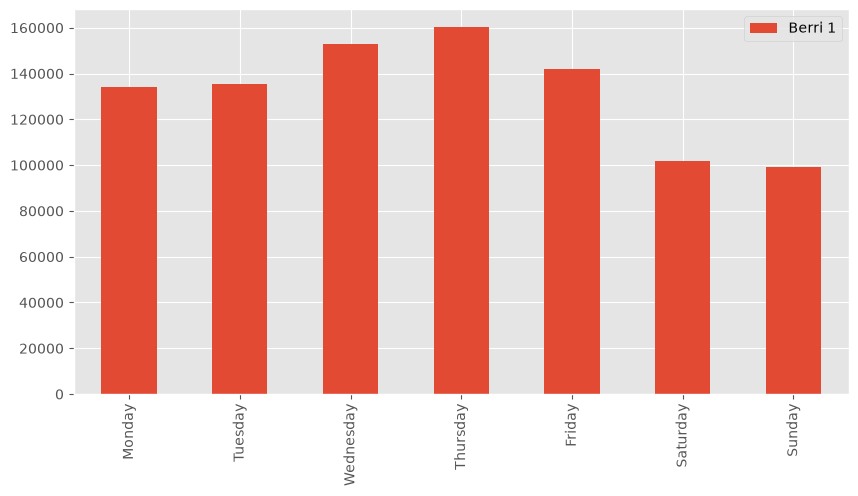

In [14]:
bikes = pd.read_csv('data/bikes.csv',
                    sep=';', encoding='latin1',
                    parse_dates=['Date'], dayfirst=True,
                    index_col='Date')
berri_bikes = bikes[['Berri 1']].copy()
berri_bikes.loc[:, 'weekday'] = berri_bikes.index.weekday
weekday_counts = berri_bikes.groupby('weekday').aggregate(sum)
weekday_counts.index = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday',
                        'Sunday']
weekday_counts.plot(kind='bar')

In [15]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
pd.options.display.max_rows = 7
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (15, 3)
plt.rcParams['font.family'] = 'sans-serif'

<Axes: xlabel='Date/Time'>

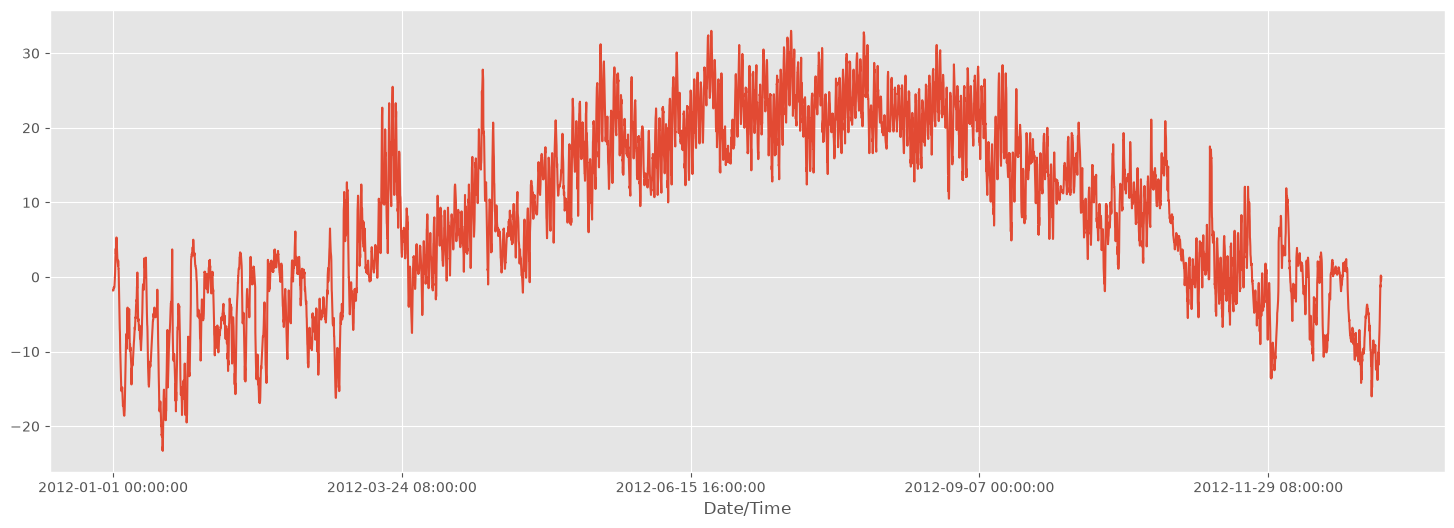

In [16]:
weather_2012_final = pd.read_csv('data/weather_2012.csv', index_col='Date/Time')
weather_2012_final['Temp (C)'].plot(figsize=(18, 6))

In [17]:
url_template = "https://climate.weather.gc.ca/climate_data/bulk_data_e.html?format=csv&stationID=5415&Year={year}&Month={month}&Day=1&timeframe=1&submit=Download+Data"

In [18]:
url = url_template.format(month=3, year=2012)
weather_mar2012 = pd.read_csv(url, skiprows=0, index_col='Date/Time (LST)', parse_dates=True,
                              encoding='utf-8')

In [19]:
weather_mar2012

,Longitude (x),Latitude (y),Station Name,Climate ID,Year,Month,Day,Time (LST),Flag,Temp (°C),...,Wind Spd Flag,Visibility (km),Visibility Flag,Stn Press (kPa),Stn Press Flag,Hmdx,Hmdx Flag,Wind Chill,Wind Chill Flag,Weather
Date/Time (LST),,,,,,,,,,,,,,,,,,,,,
2012-03-01 00:00:00,-73.75,45.47,MONTREAL/PIERRE ELLIOTT TRUDEAU INTL A,7025250,2012,3,1,00:00,NaN,-5.5,...,NaN,4.0,NaN,100.97,NaN,NaN,NaN,-13.0,NaN,Snow
2012-03-01 01:00:00,-73.75,45.47,MONTREAL/PIERRE ELLIOTT TRUDEAU INTL A,7025250,2012,3,1,01:00,NaN,-5.7,...,NaN,2.4,NaN,100.87,NaN,NaN,NaN,-13.0,NaN,Snow
2012-03-01 02:00:00,-73.75,45.47,MONTREAL/PIERRE ELLIOTT TRUDEAU INTL A,7025250,2012,3,1,02:00,NaN,-5.4,...,NaN,4.8,NaN,100.80,NaN,NaN,NaN,-13.0,NaN,Snow
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2012-03-31 21:00:00,-73.75,45.47,MONTREAL/PIERRE ELLIOTT TRUDEAU INTL A,7025250,2012,3,31,21:00,NaN,2.6,...,NaN,25.0,NaN,100.86,NaN,NaN,NaN,NaN,NaN,Clear
2012-03-31 22:00:00,-73.75,45.47,MONTREAL/PIERRE ELLIOTT TRUDEAU INTL A,7025250,2012,3,31,22:00,NaN,2.7,...,NaN,25.0,NaN,100.82,NaN,NaN,NaN,NaN,NaN,Clear
2012-03-31 23:00:00,-73.75,45.47,MONTREAL/PIERRE ELLIOTT TRUDEAU INTL A,7025250,2012,3,31,23:00,NaN,1.5,...,NaN,25.0,NaN,100.79,NaN,NaN,NaN,NaN,NaN,Clear


<Axes: xlabel='Date/Time (LST)'>

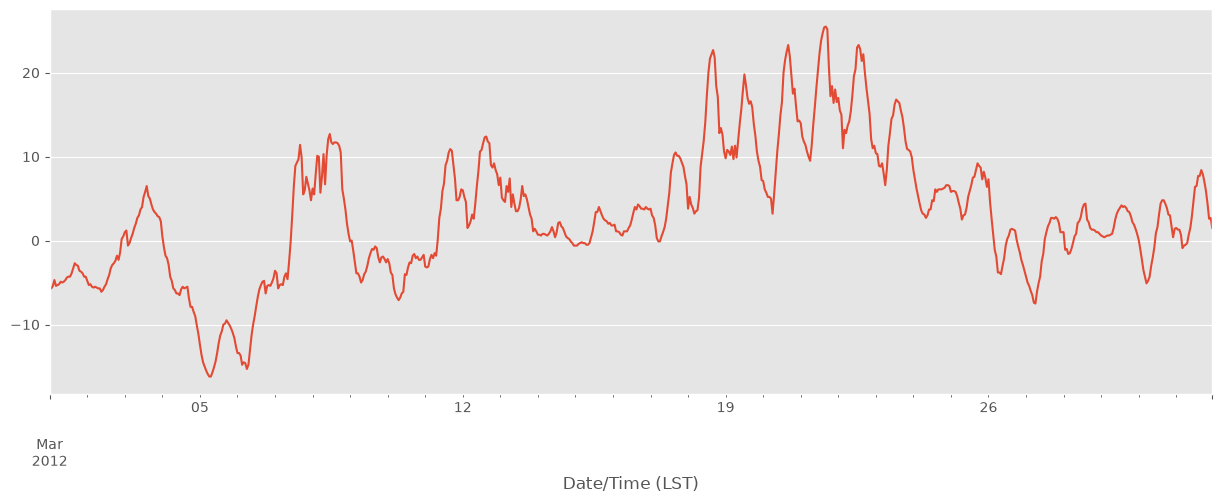

In [20]:
weather_mar2012["Temp (°C)"].plot(figsize=(15, 5))

In [21]:
weather_mar2012.columns = [
    u'Longitude (x)', u'Latitude (y)', u'Station Name', u'Climate ID',
    u'Year', u'Month', u'Day', u'Time', u'Data Quality', u'Temp (C)',
    u'Temp Flag', u'Dew Point Temp (C)', u'Dew Point Temp Flag',
    u'Rel Hum (%)', u'Rel Hum Flag', u'Precip. Amount (mm)', u'Precip. Amount Flag',
    u'Wind Dir (10s deg)', u'Wind Dir Flag',
    u'Wind Spd (km/h)', u'Wind Spd Flag', u'Visibility (km)', u'Visibility Flag',
    u'Stn Press (kPa)', u'Stn Press Flag', u'Hmdx', u'Hmdx Flag', u'Wind Chill',
    u'Wind Chill Flag', u'Weather']

In [22]:
weather_mar2012 = weather_mar2012.dropna(axis=1, how='any')
weather_mar2012[:5]

,Longitude (x),Latitude (y),Station Name,Climate ID,Year,Month,Day,Time,Temp (C),Dew Point Temp (C),Rel Hum (%),Wind Spd (km/h),Visibility (km),Stn Press (kPa),Weather
Date/Time (LST),,,,,,,,,,,,,,,
2012-03-01 00:00:00,-73.75,45.47,MONTREAL/PIERRE ELLIOTT TRUDEAU INTL A,7025250,2012,3,1,00:00,-5.5,-9.7,72,24,4.0,100.97,Snow
2012-03-01 01:00:00,-73.75,45.47,MONTREAL/PIERRE ELLIOTT TRUDEAU INTL A,7025250,2012,3,1,01:00,-5.7,-8.7,79,26,2.4,100.87,Snow
2012-03-01 02:00:00,-73.75,45.47,MONTREAL/PIERRE ELLIOTT TRUDEAU INTL A,7025250,2012,3,1,02:00,-5.4,-8.3,80,28,4.8,100.80,Snow
2012-03-01 03:00:00,-73.75,45.47,MONTREAL/PIERRE ELLIOTT TRUDEAU INTL A,7025250,2012,3,1,03:00,-4.7,-7.7,79,28,4.0,100.69,Snow
2012-03-01 04:00:00,-73.75,45.47,MONTREAL/PIERRE ELLIOTT TRUDEAU INTL A,7025250,2012,3,1,04:00,-5.4,-7.8,83,35,1.6,100.62,Snow


In [23]:
weather_mar2012 = weather_mar2012.drop(['Longitude (x)', 'Latitude (y)', 'Station Name',
                                        'Climate ID', 'Year', 'Month', 'Day', 'Time',
                                        'Data Quality'], axis=1, errors='ignore')
weather_mar2012[:5]

,Temp (C),Dew Point Temp (C),Rel Hum (%),Wind Spd (km/h),Visibility (km),Stn Press (kPa),Weather
Date/Time (LST),,,,,,,
2012-03-01 00:00:00,-5.5,-9.7,72,24,4.0,100.97,Snow
2012-03-01 01:00:00,-5.7,-8.7,79,26,2.4,100.87,Snow
2012-03-01 02:00:00,-5.4,-8.3,80,28,4.8,100.80,Snow
2012-03-01 03:00:00,-4.7,-7.7,79,28,4.0,100.69,Snow
2012-03-01 04:00:00,-5.4,-7.8,83,35,1.6,100.62,Snow


<Axes: xlabel='Hour'>

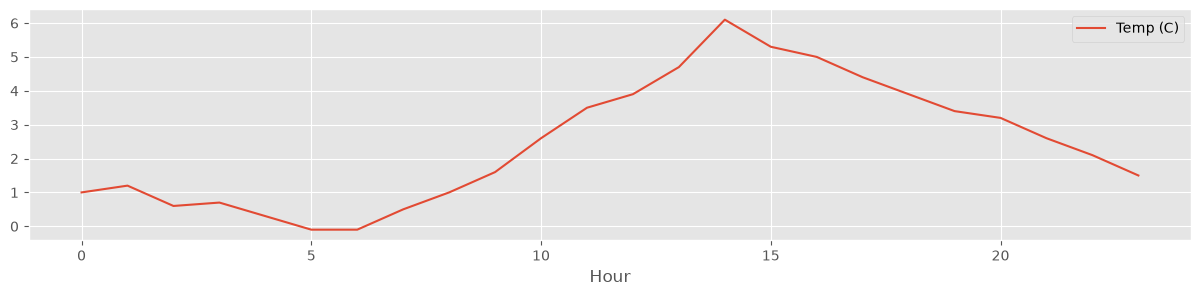

In [24]:
temperatures = weather_mar2012[[u'Temp (C)']].copy()
temperatures.loc[:, 'Hour'] = weather_mar2012.index.hour
temperatures.groupby('Hour').aggregate(np.median).plot()

In [25]:
def download_weather_month(year, month):
    url = url_template.format(year=year, month=month)
    weather_data = pd.read_csv(url, skiprows=0, index_col='Date/Time (LST)', parse_dates=True)
    weather_data = weather_data.dropna(axis=1)
    weather_data.columns = [col.replace('\xb0', '') for col in weather_data.columns]
    weather_data = weather_data.drop(['Longitude (x)', 'Latitude (y)', 'Station Name',
                                      'Climate ID', 'Year', 'Day', 'Month', 'Time (LST)',
                                      'Data Quality'], axis=1, errors='ignore')
    return weather_data

In [26]:
download_weather_month(2012, 1)[:5]

,Temp (C),Dew Point Temp (C),Rel Hum (%),Wind Spd (km/h),Visibility (km),Stn Press (kPa),Weather
Date/Time (LST),,,,,,,
2012-01-01 00:00:00,-1.8,-3.9,86,4,8.0,101.24,Fog
2012-01-01 01:00:00,-1.8,-3.7,87,4,8.0,101.24,Fog
2012-01-01 02:00:00,-1.8,-3.4,89,7,4.0,101.26,"Freezing Drizzle,Fog"
2012-01-01 03:00:00,-1.5,-3.2,88,6,4.0,101.27,"Freezing Drizzle,Fog"
2012-01-01 04:00:00,-1.5,-3.3,88,7,4.8,101.23,Fog


In [27]:
data_by_month = [download_weather_month(2012, i) for i in range(1, 13)]

In [28]:
weather_2012 = pd.concat(data_by_month)
weather_2012

,Temp (C),Dew Point Temp (C),Rel Hum (%),Wind Spd (km/h),Visibility (km),Stn Press (kPa),Weather
Date/Time (LST),,,,,,,
2012-01-01 00:00:00,-1.8,-3.9,86,4,8.0,101.24,Fog
2012-01-01 01:00:00,-1.8,-3.7,87,4,8.0,101.24,Fog
2012-01-01 02:00:00,-1.8,-3.4,89,7,4.0,101.26,"Freezing Drizzle,Fog"
...,...,...,...,...,...,...,...
2012-12-31 21:00:00,-0.5,-1.5,93,28,4.8,99.95,Snow
2012-12-31 22:00:00,-0.2,-1.8,89,28,9.7,99.91,Snow
2012-12-31 23:00:00,0.0,-2.1,86,30,11.3,99.89,Snow


In [29]:
weather_2012.to_csv('data/weather_2012_downloaded.csv')